<a href="https://colab.research.google.com/github/ldiazbusquets/retirement-sim/blob/main/notebook/retirement_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retirement Simulation in Python (Mini Project 2 → Retirement Simulator app)

FIN 414 Applied Project I · Group 6

This notebook runs the **same simulation as our web app** ([live app](https://ldiazbusquets.github.io/retirement-sim/)) in Python, the way we did [Mini Project 2](https://colab.research.google.com/drive/1CneUfRILPvuPLPJIDTyWolI1Qd1K_K1Q?usp=sharing) in Colab. It shows that the app keeps the mini project's logic:

1. the same S&P 500 data (^GSPC year-end closes, 1929–2023 → 94 annual returns),
2. the same year-by-year formula as our mini project: `balance = (balance + contribution) × (1 + return)` (deposit at the start of each year),
3. the same loops: 35 years inside 10,000 simulations,
4. the same outputs: mean, median, probability of reaching the goal, 5th and 95th percentiles, and a histogram.

Because the notebook uses the same seeded random numbers as the app, **Emma's results match the website to the dollar.**

## 1. The professor's Mini Project 2 code (unchanged)

This is the data step from the professor's [Mini Project 2 notebook](https://colab.research.google.com/drive/1CneUfRILPvuPLPJIDTyWolI1Qd1K_K1Q?usp=sharing), copied as is. It downloads the S&P 500 from Yahoo Finance and turns it into annual returns. Run it in Colab (it needs internet).

In [ ]:
import numpy as np
import pandas as pd
import random
import yfinance as yf
import time
pd.set_option('display.float_format', '{:.3f}'.format)

ticker_data = yf.Ticker('^GSPC')
ticker_df = ticker_data.history(start="1929-01-01", end="2024-01-01", interval="1d")
sp500_annual_close = ticker_df["Close"].resample("YE").last().dropna() # year-end
sp500_annual_close = sp500_annual_close.dropna()
sp500_annual_ret = sp500_annual_close.pct_change().dropna()
sp500_annual_close_list = sp500_annual_close.tolist()
sp500_annual_ret_list = sp500_annual_ret.tolist()
print("sp500_annual_ret_list: ", np.shape(sp500_annual_ret_list))
print("sp500_annual_ret_list: ", [f"{x:.4f}" for x in sp500_annual_ret_list[:10]])

## 2. The app's copy of the same data

In [2]:
import json, math, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.reset_option('display.float_format')

# The year-end closes the app uses (pulled from Yahoo Finance ^GSPC, 1929-01-01 to 2024-01-01,
# the same request as Mini Project 2). Read the copy in the repo; in Colab, fetch it from GitHub.
local = Path('../data/sp500_annual_returns.json')
if local.exists():
    data = json.loads(local.read_text())
else:
    url = 'https://raw.githubusercontent.com/ldiazbusquets/retirement-sim/main/data/sp500_annual_returns.json'
    data = json.load(urllib.request.urlopen(url))

closes = pd.DataFrame(data['year_end_close']).set_index('year')['close']
returns = closes.pct_change().dropna()          # annual return = this year's close / last year's close - 1
returns_app = pd.Series([r['return'] for r in data['annual_returns']], index=returns.index)  # the app's copy (6 decimals)

print(f"{len(returns)} annual returns, {returns.index[0]}-{returns.index[-1]}")
print(f"Largest gap between recomputed and app returns: {abs(returns - returns_app).max():.1e}")
print(f"Mean {returns_app.mean():.4%}   Std dev {returns_app.std():.4%}")
print(f"Worst {returns_app.idxmin()} ({returns_app.min():.1%})   Best {returns_app.idxmax()} ({returns_app.max():.1%})")

# If the professor's cell above ran, check that his returns and the app's are the same series.
if 'sp500_annual_ret_list' in globals():
    gap = max(abs(a - b) for a, b in zip(sp500_annual_ret_list, returns_app))
    print(f"Professor's download: {len(sp500_annual_ret_list)} returns; largest gap vs. the app's returns: {gap:.1e}")

94 annual returns, 1930-2023
Largest gap between recomputed and app returns: 5.0e-07
Mean 7.7431%   Std dev 18.9133%
Worst 1931 (-47.1%)   Best 1954 (45.0%)


## 3. Emma's inputs (the app's defaults)

In [3]:
current_age    = 30
retirement_age = 65
contribution   = 12_000      # dollars per year
timing         = 'begin'     # added at the START of each year, as in our Mini Project 2
start_balance  = 0
goal           = 1_500_000
n_sims         = 10_000
seed           = 2026

years = retirement_age - current_age
mean, sd = returns_app.mean(), returns_app.std()     # sample standard deviation (n - 1), pandas default
R = returns_app.tolist()
print(f"{years} years of contributions, mean return {mean:.4%}, std dev {sd:.4%}")

35 years of contributions, mean return 7.7431%, std dev 18.9133%


## 4. Seeded random numbers

`np.random` and the browser produce different random numbers, so a NumPy run would give *close* but not identical results. To match the app exactly, this notebook uses the same small generator the app uses (mulberry32) and the same Box-Muller step to turn uniform numbers into normal ones. Same seed → same draws → same results.

In [4]:
def mulberry32(seed):
    a = seed & 0xFFFFFFFF
    def rand():
        nonlocal a
        a = (a + 0x6D2B79F5) & 0xFFFFFFFF
        t = ((a ^ (a >> 15)) * (1 | a)) & 0xFFFFFFFF
        t = ((t + (((t ^ (t >> 7)) * (61 | t)) & 0xFFFFFFFF)) & 0xFFFFFFFF) ^ t
        return ((t ^ (t >> 14)) & 0xFFFFFFFF) / 4294967296
    return rand

def normal_return(rand):
    u1, u2 = 1 - rand(), rand()
    z = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)   # Box-Muller: one standard normal draw
    return max(mean + sd * z, -1.0)                                  # can't lose more than 100%

## 5. The simulation (same loops as Mini Project 2)

In [5]:
def simulate(contribution=contribution, years=years, start_balance=start_balance,
             n_sims=n_sims, seed=seed, timing=timing, model='normal'):
    rand = mulberry32(seed)
    outcomes = []
    for s in range(n_sims):                      # outer loop: one simulated life per pass
        balance = start_balance
        for y in range(years):                   # inner loop: one year at a time
            r = normal_return(rand) if model == 'normal' else R[math.floor(rand() * len(R))]
            if timing == 'end':
                balance = balance * (1 + r) + contribution
            else:
                balance = (balance + contribution) * (1 + r)
        outcomes.append(balance)                 # wealth at retirement for this simulation
    return np.array(outcomes)

wealth = simulate()
print(f"{len(wealth):,} simulations finished")

10,000 simulations finished


## 6. Results

In [6]:
def summary(w, goal=goal):
    return pd.Series({
        'Probability of reaching goal': f"{(w >= goal).mean():.1%}",
        'Mean':            f"${w.mean():,.0f}",
        'Median':          f"${np.median(w):,.0f}",
        '5th percentile':  f"${np.percentile(w, 5):,.0f}",
        '25th percentile': f"${np.percentile(w, 25):,.0f}",
        '75th percentile': f"${np.percentile(w, 75):,.0f}",
        '95th percentile': f"${np.percentile(w, 95):,.0f}",
    })

summary(wealth).to_frame("Emma (notebook)")

,Emma (notebook)
Probability of reaching goal,50.5%
Mean,"$2,086,941"
Median,"$1,516,204"
5th percentile,"$447,013"
25th percentile,"$903,578"
75th percentile,"$2,559,681"
95th percentile,"$5,564,160"


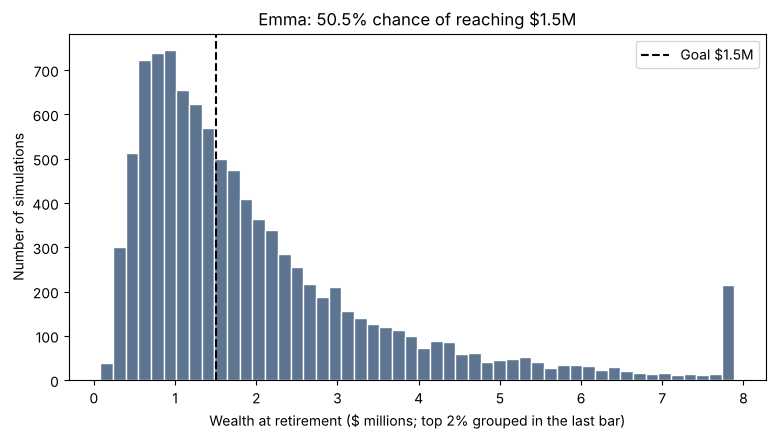

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cap = np.percentile(wealth, 98)
ax.hist(np.minimum(wealth, cap) / 1e6, bins=50, color='#5d7590', edgecolor='white')
ax.axvline(goal / 1e6, color='black', linestyle='--', label=f'Goal ${goal/1e6:.1f}M')
ax.set_xlabel('Wealth at retirement ($ millions; top 2% grouped in the last bar)')
ax.set_ylabel('Number of simulations')
ax.set_title(f"Emma: {(wealth >= goal).mean():.1%} chance of reaching ${goal/1e6:.1f}M")
ax.legend()
plt.show()

## 7. Does it match the website?

These are the numbers the live app shows for Emma's default case (seed 2026). The notebook should match them to the dollar.

In [8]:
app = {'Probability of reaching goal': 0.5046, 'Mean': 2086940.59, 'Median': 1516203.76,
       '5th percentile': 447012.84, '95th percentile': 5564159.83}
mine = {'Probability of reaching goal': (wealth >= goal).mean(), 'Mean': wealth.mean(), 'Median': np.median(wealth),
        '5th percentile': np.percentile(wealth, 5), '95th percentile': np.percentile(wealth, 95)}
check = pd.DataFrame({'Website': app, 'Notebook': mine})
check['Match'] = [abs(check.loc[k, 'Website'] - check.loc[k, 'Notebook']) < (1e-4 if 'Prob' in k else 1) for k in check.index]
fmt = lambda k, x: f"{x:.2%}" if 'Prob' in k else f"${x:,.2f}"
check.assign(
    Website=[fmt(k, x) for k, x in check['Website'].items()],
    Notebook=[fmt(k, x) for k, x in check['Notebook'].items()])

,Website,Notebook,Match
Probability of reaching goal,50.46%,50.46%,True
Mean,"$2,086,940.59","$2,086,940.59",True
Median,"$1,516,203.76","$1,516,203.76",True
5th percentile,"$447,012.84","$447,012.84",True
95th percentile,"$5,564,159.83","$5,564,159.83",True


## 8. Hand checks (answers we know without simulating)

In [9]:
# Future value of an annuity due (deposits at the start of each year), at the average return
fv_annuity_due = contribution * ((1 + mean) ** years - 1) / mean * (1 + mean)
print(f"0% returns every year: ${contribution * years:,.0f}  (12,000 x 35)")
print(f"Expected mean from the formula: ${fv_annuity_due:,.0f}   Simulated mean: ${wealth.mean():,.0f}  "
      f"({wealth.mean() / fv_annuity_due - 1:+.1%}, normal random variation)")
w_end = simulate(timing='end')
print(f"Moving deposits to the end of each year lowers the mean by {1 - w_end.mean() / wealth.mean():.1%} "
      f"(one less year of growth on each deposit; average return = {mean:.1%})")

0% returns every year: $420,000  (12,000 x 35)
Expected mean from the formula: $2,104,386   Simulated mean: $2,086,941  (-0.8%, normal random variation)


Moving deposits to the end of each year lowers the mean by 7.2% (one less year of growth on each deposit; average return = 7.7%)


## 9. What-ifs (same as the demo)

In [10]:
cases = {
    'Emma (default)':                 simulate(),
    'Save $15,000 a year':            simulate(contribution=15_000),
    'Retire at 67':                   simulate(years=37),
    'Historical years instead':       simulate(model='historical'),
}
pd.DataFrame({name: {'Chance of goal': f"{(w >= goal).mean():.1%}", 'Median': f"${np.median(w):,.0f}"} for name, w in cases.items()}).T

,Chance of goal,Median
Emma (default),50.5%,"$1,516,204"
"Save $15,000 a year",61.9%,"$1,895,255"
Retire at 67,57.1%,"$1,738,650"
Historical years instead,51.0%,"$1,534,612"


## 10. Our Mini Project 2 simulation code, unchanged

This is the simulation cell from our Mini Project 2 submission: `np.random.seed(42)`, a normal distribution with the mean and sample standard deviation of the 94 returns, deposits at the start of each year, and two loops. NumPy's random numbers differ from the app's, so the results differ slightly, by the normal sampling noise of 10,000 runs. This is test 1 in our design document: *matches the notebook within about 1–2%.*

In [11]:
sp500_annual_ret_list = returns_app.tolist() if 'sp500_annual_ret_list' not in globals() else sp500_annual_ret_list

np.random.seed(42)

# Parameters from historical S&P 500 annual returns
mu = np.mean(sp500_annual_ret_list)
sigma = np.std(sp500_annual_ret_list, ddof=1)
print(f"Historical mean: {mu:.4f}, volatility: {sigma:.4f}")

n_sims = 10_000
years = 35                 # age 30 -> 65, 35 contributions
contribution = 12_000
goal = 1_500_000

final_wealth = []          # stores 10,000 outcomes

for sim in range(n_sims):              # one simulated lifetime
    balance = 0
    for year in range(years):          # one year
        r = np.random.normal(mu, sigma)
        balance = (balance + contribution) * (1 + r)   # deposit at start of year
    final_wealth.append(balance)

final_wealth = np.array(final_wealth)

pd.DataFrame({'App / this notebook (seed 2026)': summary(wealth), 'Mini Project 2 code (seed 42)': summary(final_wealth)})

Historical mean: 0.0774, volatility: 0.1891


,App / this notebook (seed 2026),Mini Project 2 code (seed 42)
Probability of reaching goal,50.5%,50.4%
Mean,"$2,086,941","$2,086,742"
Median,"$1,516,204","$1,510,608"
5th percentile,"$447,013","$441,757"
25th percentile,"$903,578","$896,176"
75th percentile,"$2,559,681","$2,569,693"
95th percentile,"$5,564,160","$5,590,407"
